In [158]:
import pandas as pd
import numpy as np
import os

print(os.getcwd())
print(os.path.abspath("features_training_gB2.csv"))
df = pd.read_csv("features_training_gB2.csv")
X = df.replace(r"^\s*$", np.nan, regex=True).dropna(how="all")
feature_names = X.drop(columns=["band_gap", "formula_pretty", "material_id"]).columns.tolist()
X = df.drop(columns=["band_gap", "formula_pretty", "material_id"])
band_gap = df["band_gap"].to_numpy()
print(X.shape)

/Users/michaelbolarinwa/Library/CloudStorage/GoogleDrive-michaelbolarinwa11@gmail.com/My Drive/Postgraduate /EMS740P - Machine Learning and AI/Coursework/CW Code
/Users/michaelbolarinwa/Library/CloudStorage/GoogleDrive-michaelbolarinwa11@gmail.com/My Drive/Postgraduate /EMS740P - Machine Learning and AI/Coursework/CW Code/features_training_gB2.csv
(1400, 32)


In [159]:
#Extracting the specific features we want to test for, then creating a matrix out of it.
#cols = ["MagpieData range MendeleevNumber", "MagpieData range Electronegativity", "MagpieData mean CovalentRadius", "frac p valence electrons", "max ionic char", "avg ionic char"]
#X = df[cols].iloc[0:1400].T

#print(X)

In [160]:
##Step 1.1  - Calculate Covariance Matrix of the training set which is 32 features x 1400 measurements
X_num = X.select_dtypes(include="number")
X_cov_matrix = np.cov(X_num, rowvar=False)
#print(X_cov_matrix)
#print(X_cov_matrix.shape)

#Step 1.2 - Find the eigenvectors, X_eigvec, of the covariance matrix, X_cov_matrix
X_eigval, X_eigvec = np.linalg.eig(X_cov_matrix)
#print(X_eigvec)
#print(X_eigval)
#print(X_eigval.shape)
#print(X_eigvec.shape)

order = np.argsort(X_eigval)[::-1]
X_eigval = X_eigval[order]
X_eigvec = X_eigvec[:, order]

pc1 = X_eigvec[:, 0]
pc2 = X_eigvec[:, 1]
pc3 = X_eigvec[:, 2]

print(X_eigval[0])

importance = sorted(
    zip(feature_names, np.abs(pc1)),
    key=lambda item: item[1],
    reverse=True
)

importance1 = sorted(
    zip(feature_names, np.abs(pc2)),
    key=lambda item: item[1],
    reverse=True
)

print("\nTop 10 features contributing to PC1:")
for name, weight in importance[:10]:
    print(f"{name}: {weight:.4f}")

print("\nTop 10 features contributing to PC2:")
for name, weight in importance1[:10]:
    print(f"{name}: {weight:.4f}")

(1343.1039598221014+0j)

Top 10 features contributing to PC1:
MagpieData range CovalentRadius: 0.7917
MagpieData range MendeleevNumber: 0.4677
MagpieData avg_dev CovalentRadius: 0.2329
MagpieData mean CovalentRadius: 0.2270
MagpieData avg_dev MendeleevNumber: 0.1646
MagpieData mean MendeleevNumber: 0.1425
MagpieData range NdValence: 0.0272
MagpieData avg_dev NdValence: 0.0140
MagpieData mean NdValence: 0.0120
avg d valence electrons: 0.0120

Top 10 features contributing to PC2:
MagpieData range MendeleevNumber: 0.6889
MagpieData range CovalentRadius: 0.5586
MagpieData mean MendeleevNumber: 0.3112
MagpieData avg_dev MendeleevNumber: 0.2952
MagpieData mean CovalentRadius: 0.1406
MagpieData range NfValence: 0.0815
MagpieData avg_dev CovalentRadius: 0.0261
MagpieData avg_dev NfValence: 0.0243
MagpieData range NdValence: 0.0173
MagpieData mean NfValence: 0.0161


In [161]:
#Step 2 - Choose the K "largest" eigenvectors. These are our principal components
#PC1 = 1343.166
#PC2 = 432.980
#PC3 = 213.451
#PC4 = 39.172
#PC5 = 27.806

#PC1-3 make upn 98.7% of the total variance

combined_weight = np.abs(pc1) + np.abs(pc2)

importance_m2 = sorted(
    zip(feature_names, combined_weight),
    key=lambda item: item[1],
    reverse=True
)

print("Top 10 features for m=2:")

for name, score in importance_m2[:10]:
    print(f"{name}: {score:.4f}")

Top 10 features for m=2:
MagpieData range CovalentRadius: 1.3503
MagpieData range MendeleevNumber: 1.1566
MagpieData avg_dev MendeleevNumber: 0.4599
MagpieData mean MendeleevNumber: 0.4537
MagpieData mean CovalentRadius: 0.3676
MagpieData avg_dev CovalentRadius: 0.2589
MagpieData range NfValence: 0.0823
MagpieData range NdValence: 0.0445
MagpieData avg_dev NfValence: 0.0258
MagpieData avg_dev NdValence: 0.0241


/opt/anaconda3/lib/python3.14/site-packages/matplotlib/cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/opt/anaconda3/lib/python3.14/site-packages/matplotlib/cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


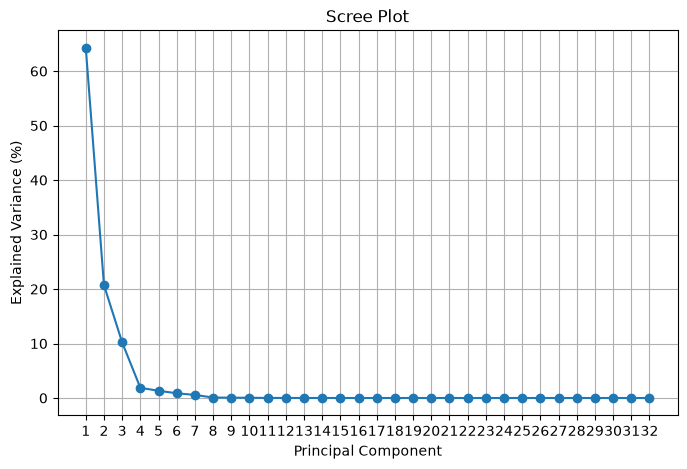

Variance explained by PC1 and PC2: 84.95+0.00j%


In [162]:
import matplotlib.pyplot as plt

explained_variance_ratio = X_eigval / np.sum(X_eigval)

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(X_eigval) + 1),
    explained_variance_ratio * 100,
    marker="o"
)
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("Scree Plot")
plt.xticks(range(1, len(X_eigval) + 1))
plt.grid(True)
plt.show()

print(
    "Variance explained by PC1 and PC2:",
    f"{np.sum(explained_variance_ratio[:2]) * 100:.2f}%"
)

/var/folders/mf/jj3pxx4569n4dp85sxg3bjyw0000gq/T/ipykernel_86123/583890036.py:2: ComplexWarning: Casting complex values to real discards the imaginary part
  V_array = np.asarray(X_eigvec, dtype=float)


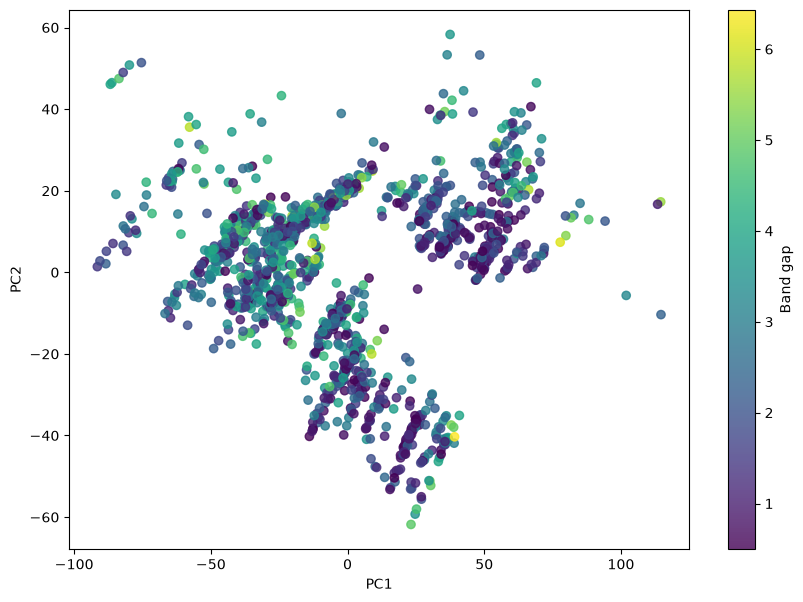

In [164]:
X_array = np.asarray(X, dtype=float)
V_array = np.asarray(X_eigvec, dtype=float)

X_centred = X_array - X_array.mean(axis=0)

X_pca = X_centred @ V_array[:, :3]
#fig = plt.figure(figsize=(10, 7))
#ax = fig.add_subplot(111, projection="3d")
fig, ax = plt.subplots(figsize=(10, 7))

scatter = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    #X_pca[:, 2],
    #c=df["band_gap"].to_numpy(),
    c = band_gap,
    cmap="viridis",
    alpha=0.8
)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
#ax.set_zlabel("PC3")
#ax.set_title("3D PCA of Materials")
fig.colorbar(scatter, ax=ax, label="Band gap")
plt.show()

